# Conditions de validation du jalon S2 (PFA 07)

Ce notebook produit les preuves demandées par l'expertise du rapport n°2 :

| Recommandation | Contenu |
|---|---|
| **R2** | `included.csv` et `reserved.csv` ; comparaison statistique des images retenues (4 870) et réservées (2 339) ; décision écrite |
| **R5** | Dépendance entre source d'acquisition et classe (V de Cramér, information mutuelle normalisée) |
| **R4** | Publication des groupes et clusters ; test unitaire de la fusion transitive ; sensibilité au seuil de Hamming ; détection de transformations |

**Prérequis :** `audit/pv/manifest.csv` et les sorties du notebook de partitions (`partition.csv`, `groups.csv`, `reserve_non_cartographiee.csv`).

**Règle :** ce notebook **ne modifie aucune partition**. Il documente, mesure et propose ; toute révision du protocole doit être décidée et versionnée à part.

## 0. Configuration

In [1]:
from pathlib import Path

MANIFEST = Path("audit/pv/manifest.csv")
PART_DIR = Path("partitions/pv")                        # partition.csv, groups.csv, reserve_non_cartographiee.csv
PV_ROOT = Path("PlantVillage-Dataset/raw/color")        # pour le test de transformations et les paires d'images
OUT = Path("conditions_s2")
SEED = 42
N_SYNTH = 200                                           # images utilisées pour le test de transformations

## 1. Chargement et construction de `included.csv` / `reserved.csv` (R2)

In [2]:
import hashlib, json, re, sys, platform
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageEnhance, ImageFilter, ImageOps
from IPython.display import display

OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50, "display.width", 200)

man = pd.read_csv(MANIFEST)
part = pd.read_csv(PART_DIR / "partition.csv")
res = pd.read_csv(PART_DIR / "reserve_non_cartographiee.csv")
groups = pd.read_csv(PART_DIR / "groups.csv")

METRICS = ["width", "height", "mean_lum", "contrast", "blur_lapvar", "border_std", "dhash"]
mm = man[["image_id"] + METRICS]


def leaf_key(relpath: str) -> str:
    stem = relpath.split("/")[-1].rsplit(".", 1)[0]
    return (stem.split("___", 1)[1] if "___" in stem else stem).lower().strip()


def source_of(relpath: str) -> str:
    return re.split(r"\s+(?:leaf\b|\d)", leaf_key(relpath), maxsplit=1)[0]


inc = part.merge(mm, on="image_id", how="left")
inc["statut"] = "inclus"
rsv = res.merge(mm, on="image_id", how="left")
rsv["statut"] = "reserve"
inc["source"] = inc["relpath"].map(source_of)
assert not (set(inc["image_id"]) & set(rsv["image_id"])), "Une image est à la fois incluse et réservée"

all_ = pd.concat([inc, rsv], ignore_index=True)
print(f"Images éligibles : {len(all_)} = {len(inc)} incluses (partitionnées) + {len(rsv)} réservées.")
print(f"Part réservée : {100 * len(rsv) / len(all_):.1f} %")

inc[["image_id", "relpath", "class_retained", "source", "group_id", "partition"]].to_csv(OUT / "included.csv", index=False)
rsv[["image_id", "relpath", "class_retained", "source"]].to_csv(OUT / "reserved.csv", index=False)

tab = all_.groupby(["class_retained", "statut"]).size().unstack(fill_value=0)
tab["total"] = tab.sum(axis=1)
tab["% réservé"] = (100 * tab["reserve"] / tab["total"]).round(1)
display(tab)
print("Tableau 1 - Images incluses et réservées, par classe retenue.")
tab.to_csv(OUT / "effectifs_inclus_reserve.csv")

Images éligibles : 7209 = 4870 incluses (partitionnées) + 2339 réservées.
Part réservée : 32.4 %


statut,inclus,reserve,total,% réservé
class_retained,,,,
alternariose_precoce,999,1,1000,0.1
cladosporiose,952,0,952,0.0
mildiou_tardif,920,981,1901,51.6
saine,999,586,1585,37.0
septoriose,1000,771,1771,43.5


Tableau 1 - Images incluses et réservées, par classe retenue.


## 2. Les images réservées sont-elles représentatives ? (R2)

On compare, par classe, la **source d'acquisition** et les métriques d'image (luminance, contraste, flou, uniformité du fond). Pour chaque métrique, l'**AUC** mesure la probabilité qu'une image incluse ait une valeur supérieure à celle d'une image réservée : **0,5 = aucune différence** ; repère indicatif : un écart à 0,5 supérieur à 0,15 signale une différence notable. Toutes les images de PlantVillage font 256 × 256 pixels, la résolution n'est donc pas discriminante.

Résolutions distinctes : [(256, 256)]


inclus                                                     réserve                                                                        
                     crnl_l.mold matt.s_cg rs_erly.b rs_hl rs_late.b 2700323949_95aa2eaa01_o cg1 gh_hl ghlb ghlb2 ghlb2es ghlb_ps jr_sept.l.s keller.st_cg rs_erly.b
class_retained                                                                                                                                                      
alternariose_precoce           0         0       999     0         0                       0   0     0    0     0       0       0           0            0         1
cladosporiose                952         0         0     0         0                       0   0     0    0     0       0       0           0            0         0
mildiou_tardif                 0         0         0     0       920                       0   0     2   66   740      27     146           0            0         0
saine                          0         0         0   999         0                       1   1   584    0     0       0       0           0            0         0
septoriose                     0      1000         0     0         0                       0   0     0    0     0       0       0         497          274         0

Tableau 2 - Sources d'acquisition par classe, dans les images incluses et dans les images réservées.


,classe,métrique,médiane incluses,médiane réservées,AUC,écart notable
0,mildiou_tardif,mean_lum,119.01,118.35,0.57,False
1,mildiou_tardif,contrast,49.38,24.08,0.91,True
2,mildiou_tardif,blur_lapvar,1634.84,487.99,0.98,True
3,mildiou_tardif,border_std,39.60,20.17,0.87,True
4,saine,mean_lum,117.21,115.24,0.59,False
5,saine,contrast,38.99,19.37,1.00,True
6,saine,blur_lapvar,3913.77,816.60,1.00,True
7,saine,border_std,27.86,22.29,0.81,True
8,septoriose,mean_lum,135.67,121.65,0.77,True
9,septoriose,contrast,35.78,36.03,0.52,False


Tableau 3 - Comparaison incluses / réservées par classe (AUC ; 0,5 = aucune différence).


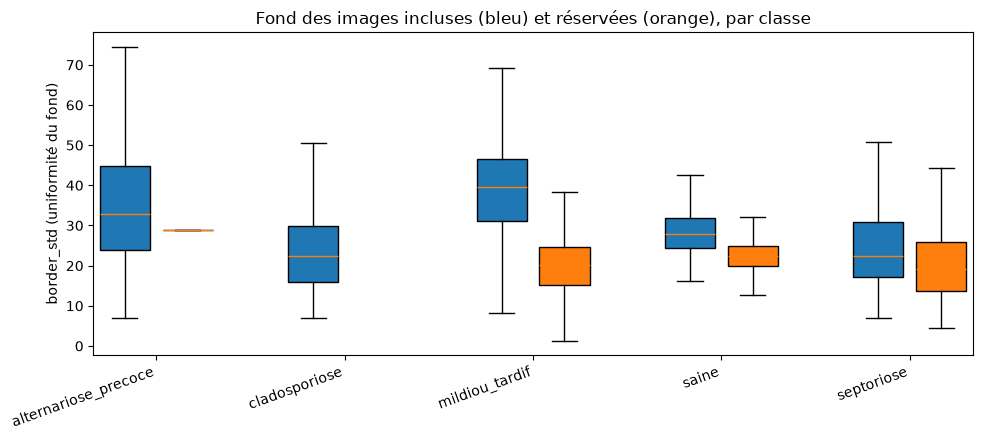

Figure 1 - Distribution de border_std dans les images incluses (bleu) et réservées (orange) ; une absence de boîte orange indique qu'il n'y a pas assez d'images réservées dans cette classe.


In [3]:
print("Résolutions distinctes :", sorted(set(zip(all_["width"], all_["height"]))))

src = pd.concat({"inclus": pd.crosstab(inc["class_retained"], inc["source"]),
                 "réserve": pd.crosstab(rsv["class_retained"], rsv["image_id"].map(lambda i: source_of(i.split(":", 1)[1])))}, axis=1).fillna(0).astype(int)
display(src)
print("Tableau 2 - Sources d'acquisition par classe, dans les images incluses et dans les images réservées.")
src.to_csv(OUT / "sources_inclus_reserve.csv")


def auc(a: pd.Series, b: pd.Series) -> float:
    x = pd.concat([a, b], ignore_index=True)
    r = x.rank(method="average")
    n1, n2 = len(a), len(b)
    return float((r.iloc[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n2))


rows = []
for cls, g in all_.groupby("class_retained"):
    a, b = g[g["statut"] == "inclus"], g[g["statut"] == "reserve"]
    if len(b) < 5:
        continue
    for m in ["mean_lum", "contrast", "blur_lapvar", "border_std"]:
        rows.append({"classe": cls, "métrique": m, "médiane incluses": round(a[m].median(), 2),
                     "médiane réservées": round(b[m].median(), 2), "AUC": round(auc(a[m], b[m]), 2),
                     "écart notable": abs(auc(a[m], b[m]) - 0.5) > 0.15})
cmp_ = pd.DataFrame(rows)
display(cmp_)
print("Tableau 3 - Comparaison incluses / réservées par classe (AUC ; 0,5 = aucune différence).")
cmp_.to_csv(OUT / "comparaison_inclus_reserve.csv", index=False)

classes = sorted(all_["class_retained"].unique())
fig, ax = plt.subplots(figsize=(10, 4.5))
for k, st in enumerate(["inclus", "reserve"]):
    data = [all_[(all_["class_retained"] == c) & (all_["statut"] == st)]["border_std"].dropna() for c in classes]
    pos = [i * 3 + k for i in range(len(classes))]
    bp = ax.boxplot(data, positions=pos, widths=0.8, showfliers=False, patch_artist=True)
    for box in bp["boxes"]:
        box.set_facecolor("#1f77b4" if st == "inclus" else "#ff7f0e")
ax.set_xticks([i * 3 + 0.5 for i in range(len(classes))])
ax.set_xticklabels(classes, rotation=20, ha="right")
ax.set_ylabel("border_std (uniformité du fond)")
ax.set_title("Fond des images incluses (bleu) et réservées (orange), par classe")
plt.tight_layout()
plt.savefig(OUT / "fig_inclus_reserve_border_std.png", dpi=150)
plt.show()
print("Figure 1 - Distribution de border_std dans les images incluses (bleu) et réservées (orange) ; une absence de boîte orange indique qu'il n'y a pas assez d'images réservées dans cette classe.")

## 3. Dépendance entre source et classe (R5)

Le **V de Cramér** vaut 0 si la source n'apprend rien sur la classe et **1 si la source détermine entièrement la classe**. L'**information mutuelle normalisée** (NMI) donne la part de l'incertitude sur la classe levée par la connaissance de la source.

In [4]:
def cramers_v(ct: pd.DataFrame) -> float:
    obs = ct.to_numpy(float)
    n = obs.sum()
    exp = obs.sum(1, keepdims=True) * obs.sum(0, keepdims=True) / n
    chi2 = (((obs - exp) ** 2) / np.where(exp > 0, exp, 1)).sum()
    k = min(obs.shape) - 1
    return float(np.sqrt(chi2 / (n * k))) if k > 0 else float("nan")


def nmi(ct: pd.DataFrame) -> float:
    p = ct.to_numpy(float)
    p = p / p.sum()
    px, py = p.sum(1, keepdims=True), p.sum(0, keepdims=True)
    nz = p > 0
    mi = float((p[nz] * np.log(p[nz] / (px @ py)[nz])).sum())
    hx = float(-(px[px > 0] * np.log(px[px > 0])).sum())
    return mi / hx if hx > 0 else float("nan")


all_["source"] = all_["relpath"].map(source_of)
dep = []
for name, d in [("incluses (4 870)", all_[all_["statut"] == "inclus"]), ("réservées", all_[all_["statut"] == "reserve"]), ("ensemble éligible", all_)]:
    ct = pd.crosstab(d["class_retained"], d["source"])
    dep.append({"ensemble": name, "images": len(d), "sources": ct.shape[1],
                "V de Cramér": round(cramers_v(ct), 3), "NMI": round(nmi(ct), 3)})
dep = pd.DataFrame(dep)
display(dep)
print("Tableau 4 - Dépendance entre source d'acquisition et classe (1 = la source détermine la classe).")
dep.to_csv(OUT / "dependance_source_classe.csv", index=False)

disp = all_.groupby(["statut", "class_retained"])["border_std"].agg(["median", "std"]).round(2)
display(disp)
print("Tableau 5 - Variété des fonds (border_std : médiane et écart-type) par classe et par statut.")

,ensemble,images,sources,V de Cramér,NMI
0,incluses (4 870),4870,5,1.000,1.000
1,réservées,2339,10,0.999,0.995
2,ensemble éligible,7209,14,1.000,0.999


Tableau 4 - Dépendance entre source d'acquisition et classe (1 = la source détermine la classe).


median    std
statut  class_retained                     
inclus  alternariose_precoce   32.83  14.35
        cladosporiose          22.41   9.87
        mildiou_tardif         39.60  12.03
        saine                  27.86   5.56
        septoriose             22.51   9.75
reserve alternariose_precoce   28.97    NaN
        mildiou_tardif         20.17  10.80
        saine                  22.29   4.12
        septoriose             19.09   9.74

Tableau 5 - Variété des fonds (border_std : médiane et écart-type) par classe et par statut.


## 4. Publication des groupes et des clusters (R4)

On publie les clusters et les tailles de groupes, pas seulement leur nombre.

In [5]:
man_cl = man[man["near_dup_cluster"] >= 0][["image_id", "near_dup_cluster", "class_retained"]].copy()
statut_of = dict(zip(inc["image_id"], ["inclus"] * len(inc)))
statut_of.update(dict(zip(rsv["image_id"], ["reserve"] * len(rsv))))
man_cl["statut"] = man_cl["image_id"].map(statut_of).fillna("hors périmètre ou exclue")
man_cl = man_cl.merge(inc[["image_id", "group_id", "partition"]], on="image_id", how="left")
man_cl.sort_values(["near_dup_cluster", "image_id"]).to_csv(OUT / "clusters_membres.csv", index=False)

touch = man_cl.groupby("near_dup_cluster")["statut"].agg(
    membres="size", inclus=lambda x: int((x == "inclus").sum()),
    reserve=lambda x: int((x == "reserve").sum()),
    hors=lambda x: int((x == "hors périmètre ou exclue").sum())).reset_index()
print(f"{len(touch)} cluster(s) de quasi-doublons dans l'audit ; {int((touch['inclus'] > 0).sum())} touchent des images incluses ; "
      f"{int((touch['inclus'] > 1).sum())} contiennent plusieurs images incluses.")
display(touch[touch["inclus"] > 0] if (touch["inclus"] > 0).any() else touch.head(10))
print("Tableau 6 - Clusters de quasi-doublons touchant la cohorte principale (membres par statut).")

sizes = groups["n_images"].value_counts().sort_index().rename("n_groupes").to_frame()
sizes.index.name = "images par groupe"
display(sizes)
print("Tableau 7 - Distribution de la taille des groupes (feuilles après fusion).")
sizes.to_csv(OUT / "tailles_groupes.csv")

print("Groupes issus d'une fusion de plusieurs feuilles :", int((groups["n_leaf_ids"] > 1).sum()))
print("Groupes multi-classes :", int(groups["classes"].str.contains(";").sum()))

33 cluster(s) de quasi-doublons dans l'audit ; 1 touchent des images incluses ; 0 contiennent plusieurs images incluses.


,near_dup_cluster,membres,inclus,reserve,hors
4,4,2,1,0,1


Tableau 6 - Clusters de quasi-doublons touchant la cohorte principale (membres par statut).


,n_groupes
images par groupe,
3,2
4,1216


Tableau 7 - Distribution de la taille des groupes (feuilles après fusion).
Groupes issus d'une fusion de plusieurs feuilles : 0
Groupes multi-classes : 0


## 5. Test unitaire de la fusion transitive (R4)

Si A est proche de B et B proche de C, sans que A le soit de C, les trois doivent former **un seul groupe**, donc rester dans la **même partition**. La fonction ci-dessous est la même logique d'union que celle du notebook de partitions.

In [6]:
def groups_from_links(nodes, links):
    parent = {n: n for n in nodes}

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    for a, b in links:
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    return {n: find(n) for n in nodes}


# 1. chaîne A-B, B-C sans lien direct A-C
g = groups_from_links(["A", "B", "C", "D"], [("A", "B"), ("B", "C")])
assert g["A"] == g["B"] == g["C"], "La transitivité n'est pas respectée"
assert g["D"] != g["A"], "Un élément isolé ne doit pas être fusionné"

# 2. chaîne longue
chain = [(str(i), str(i + 1)) for i in range(9)]
g = groups_from_links([str(i) for i in range(10)], chain)
assert len(set(g.values())) == 1, "Une chaîne de 10 éléments doit former un seul groupe"

# 3. deux composantes distinctes
g = groups_from_links(list("ABCDEF"), [("A", "B"), ("B", "C"), ("D", "E")])
assert len({g[x] for x in "ABC"}) == 1 and len({g[x] for x in "DE"}) == 1 and g["A"] != g["D"] and g["F"] not in (g["A"], g["D"])

# 4. l'affectation d'une partition par groupe garde les membres ensemble
part_of_group = {r: ("train" if i % 2 == 0 else "test") for i, r in enumerate(sorted(set(g.values())))}
assert len({part_of_group[g[x]] for x in "ABC"}) == 1
print("Tous les tests unitaires de la fusion transitive réussissent.")

Tous les tests unitaires de la fusion transitive réussissent.


## 6. Sensibilité au seuil de Hamming (R4)

Pour chaque seuil de 0 à 7, on compte, **parmi les images incluses**, les paires de quasi-doublons qui se retrouvent dans des partitions différentes, et les composantes connexes à cheval. La règle actuelle (seuil 4) doit donner 0 ; des valeurs non nulles à 5, 6 ou 7 désignent des fuites potentielles à inspecter.

,seuil de Hamming,paires,paires dans des groupes différents,paires entre partitions,images concernées,composantes à cheval
0,0,0,0,0,0,0
1,1,0,0,0,0,0
2,2,0,0,0,0,0
3,3,0,0,0,0,0
4,4,0,0,0,0,0
5,5,1,1,0,0,0
6,6,7,6,4,8,4
7,7,20,17,11,22,11


Tableau 8 - Sensibilité du regroupement au seuil de Hamming (images incluses ; règle actuelle : seuil 4).
11 paire(s) entre partitions à distance <= 7.


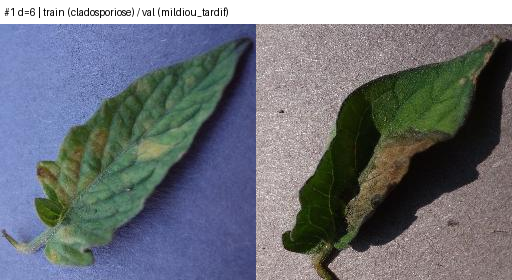

Figure - Paire #1 entre partitions (distance 6) : même feuille ? Si oui, c'est une fuite à traiter.


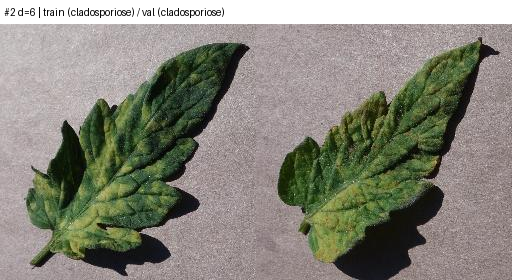

Figure - Paire #2 entre partitions (distance 6) : même feuille ? Si oui, c'est une fuite à traiter.


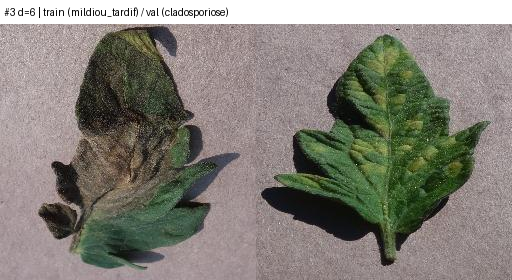

Figure - Paire #3 entre partitions (distance 6) : même feuille ? Si oui, c'est une fuite à traiter.


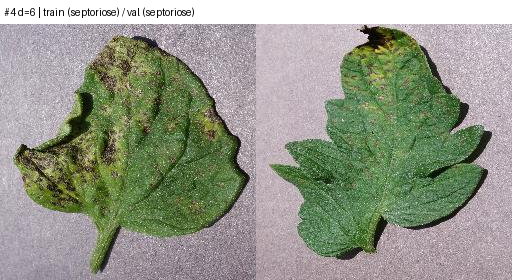

Figure - Paire #4 entre partitions (distance 6) : même feuille ? Si oui, c'est une fuite à traiter.


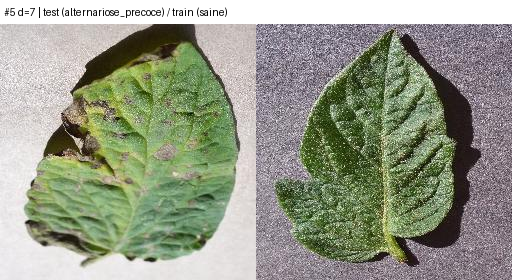

Figure - Paire #5 entre partitions (distance 7) : même feuille ? Si oui, c'est une fuite à traiter.


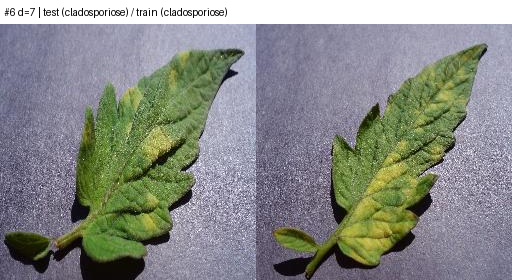

Figure - Paire #6 entre partitions (distance 7) : même feuille ? Si oui, c'est une fuite à traiter.


In [7]:
_POP16 = np.array([bin(i).count("1") for i in range(1 << 16)], dtype=np.uint8)


def popcount64(x):
    m = np.uint64(0xFFFF)
    return (_POP16[x & m] + _POP16[(x >> np.uint64(16)) & m] + _POP16[(x >> np.uint64(32)) & m] + _POP16[(x >> np.uint64(48)) & m])


def near_pairs_with_dist(hashes, tmax=7):
    """Paires (a, b) à distance <= tmax, avec leur distance (blocs de 8 bits, valable pour tmax <= 7)."""
    out = {}
    for k in range(8):
        keys = (hashes >> np.uint64(8 * k)) & np.uint64(0xFF)
        for key in np.unique(keys):
            idx = np.nonzero(keys == key)[0]
            if len(idx) < 2:
                continue
            h = hashes[idx]
            for s in range(0, len(idx), 512):
                d = popcount64(h[s:s + 512][:, None] ^ h[None, :])
                ii, jj = np.nonzero(d <= tmax)
                for i, j in zip(ii, jj):
                    a, b = int(idx[s + i]), int(idx[j])
                    if a < b:
                        out[(a, b)] = int(d[i, j])
    return out


inc = inc.reset_index(drop=True)
H = np.array([int(h, 16) for h in inc["dhash"]], dtype=np.uint64)
pairs = near_pairs_with_dist(H, 7)
parts = inc["partition"].to_numpy()
grp = inc["group_id"].to_numpy()

rows = []
for t in range(0, 8):
    sel = [(a, b) for (a, b), d in pairs.items() if d <= t]
    cross = [(a, b) for a, b in sel if parts[a] != parts[b]]
    comp = groups_from_links(list(range(len(inc))), sel)
    comp_parts = pd.Series(parts).groupby(pd.Series(comp)).nunique()
    rows.append({"seuil de Hamming": t, "paires": len(sel),
                 "paires dans des groupes différents": sum(grp[a] != grp[b] for a, b in sel),
                 "paires entre partitions": len(cross),
                 "images concernées": len({i for p in cross for i in p}),
                 "composantes à cheval": int((comp_parts > 1).sum())})
sens = pd.DataFrame(rows)
display(sens)
print("Tableau 8 - Sensibilité du regroupement au seuil de Hamming (images incluses ; règle actuelle : seuil 4).")
sens.to_csv(OUT / "sensibilite_seuil_dhash.csv", index=False)

cross7 = sorted(((d, a, b) for (a, b), d in pairs.items() if parts[a] != parts[b]))
print(f"{len(cross7)} paire(s) entre partitions à distance <= 7.")


def pair_sheet(p1, p2, title, tile=256):
    sheet = Image.new("RGB", (2 * tile, tile + 24), "white")
    ImageDraw.Draw(sheet).text((4, 6), title, fill="black")
    for k, p in enumerate((p1, p2)):
        with Image.open(p) as im:
            im = im.convert("RGB")
            im.thumbnail((tile, tile))
            sheet.paste(im, (k * tile + (tile - im.width) // 2, 24 + (tile - im.height) // 2))
    return sheet


(OUT / "paires_entre_partitions").mkdir(exist_ok=True)
for n, (d, a, b) in enumerate(cross7[:6], 1):
    s = pair_sheet(PV_ROOT / inc.at[a, "relpath"], PV_ROOT / inc.at[b, "relpath"],
                   f"#{n} d={d} | {parts[a]} ({inc.at[a, 'class_retained']}) / {parts[b]} ({inc.at[b, 'class_retained']})")
    s.save(OUT / "paires_entre_partitions" / f"paire_{n:02d}.png")
    display(s)
    print(f"Figure - Paire #{n} entre partitions (distance {d}) : même feuille ? Si oui, c'est une fuite à traiter.")

## 6 bis. Sensibilité aux retournements et rotations (R4)

Le dHash d'origine ne détecte pas une image retournée ou tournée (voir la section 7). On calcule donc, pour chaque image incluse, le hash de ses **8 orientations**, puis on compare l'orientation d'origine de chaque image aux 8 orientations de toutes les autres, et on compte les paires proches situées dans des partitions différentes.

In [8]:
TR = Image.Transpose
ORIENTS = [None, TR.FLIP_LEFT_RIGHT, TR.FLIP_TOP_BOTTOM, TR.ROTATE_90, TR.ROTATE_180, TR.ROTATE_270, TR.TRANSPOSE, TR.TRANSVERSE]
RES8 = Image.Resampling.LANCZOS


def dhash8(im) -> int:
    s_ = np.asarray(im.convert("L").resize((9, 8), RES8), dtype=np.int16)
    bits = (s_[:, 1:] > s_[:, :-1]).ravel()
    return int("".join("1" if b else "0" for b in bits), 2)


hv = np.zeros(len(inc) * 8, dtype=np.uint64)
owner = np.repeat(np.arange(len(inc)), 8)
for n_, r_ in enumerate(inc.itertuples()):
    with Image.open(PV_ROOT / r_.relpath) as im_:
        im_.load()
        for k_, t_ in enumerate(ORIENTS):
            hv[n_ * 8 + k_] = dhash8(im_ if t_ is None else im_.transpose(t_))

pv8 = near_pairs_with_dist(hv, 7)
best8 = {}
for (u, v), d_ in pv8.items():
    if u % 8 != 0 and v % 8 != 0:
        continue          # on compare l'orientation d'origine d'une image à toutes les orientations de l'autre
    a_, b_ = int(owner[u]), int(owner[v])
    if a_ == b_:
        continue
    key_ = (min(a_, b_), max(a_, b_))
    if key_ not in best8 or d_ < best8[key_]:
        best8[key_] = d_

rows8 = []
for t in range(0, 8):
    sel = [(a_, b_) for (a_, b_), d_ in best8.items() if d_ <= t]
    cross = [(a_, b_) for a_, b_ in sel if parts[a_] != parts[b_]]
    rows8.append({"seuil de Hamming": t, "paires (8 orientations)": len(sel),
                  "paires entre partitions": len(cross),
                  "images concernées": len({i_ for p_ in cross for i_ in p_})})
sens8 = pd.DataFrame(rows8)
display(sens8)
print("Tableau 9 - Paires d'images proches en tenant compte des retournements et rotations (images incluses).")
sens8.to_csv(OUT / "sensibilite_seuil_dhash_8_orientations.csv", index=False)

,seuil de Hamming,paires (8 orientations),paires entre partitions,images concernées
0,0,0,0,0
1,1,0,0,0
2,2,0,0,0
3,3,0,0,0
4,4,0,0,0
5,5,7,4,7
6,6,29,15,27
7,7,88,51,88


Tableau 9 - Paires d'images proches en tenant compte des retournements et rotations (images incluses).


## 7. Quelles transformations le dHash détecte-t-il ? (R4)

On applique des transformations connues à 200 images incluses et on mesure la distance au hash de l'original. Cela quantifie la limite signalée par l'encadrant (recadrages, luminosité, rotations).

In [9]:
RES = Image.Resampling.LANCZOS


def dhash(im) -> int:
    s = np.asarray(im.convert("L").resize((9, 8), RES), dtype=np.int16)
    bits = (s[:, 1:] > s[:, :-1]).ravel()
    return int("".join("1" if b else "0" for b in bits), 2)


def jpeg(im, q):
    import io
    buf = io.BytesIO()
    im.convert("RGB").save(buf, "JPEG", quality=q)
    buf.seek(0)
    return Image.open(buf).convert("RGB")


def crop_center(im, frac):
    w, h = im.size
    cw, ch = int(w * frac), int(h * frac)
    x, y = (w - cw) // 2, (h - ch) // 2
    return im.crop((x, y, x + cw, y + ch)).resize((w, h), RES)


TRANSFORMS = {
    "recompression JPEG (qualité 50)": lambda im: jpeg(im, 50),
    "redimensionnement 128 px puis 256 px": lambda im: im.resize((128, 128), RES).resize((256, 256), RES),
    "luminosité x 0,8": lambda im: ImageEnhance.Brightness(im).enhance(0.8),
    "luminosité x 1,2": lambda im: ImageEnhance.Brightness(im).enhance(1.2),
    "contraste x 0,8": lambda im: ImageEnhance.Contrast(im).enhance(0.8),
    "flou gaussien (rayon 1)": lambda im: im.filter(ImageFilter.GaussianBlur(1)),
    "recadrage centré 90 %": lambda im: crop_center(im, 0.90),
    "recadrage centré 75 %": lambda im: crop_center(im, 0.75),
    "retournement horizontal": lambda im: ImageOps.mirror(im),
    "rotation de 90 degrés": lambda im: im.rotate(90, expand=True),
}

sample = inc.sample(min(N_SYNTH, len(inc)), random_state=SEED)
dist = {k: [] for k in TRANSFORMS}
for r in sample.itertuples():
    with Image.open(PV_ROOT / r.relpath) as im:
        im = im.convert("RGB")
        h0 = dhash(im)
        for name, fn in TRANSFORMS.items():
            dist[name].append(bin(h0 ^ dhash(fn(im))).count("1"))

rows = [{"transformation": k, "distance médiane": float(np.median(v)),
         "détectée à seuil 4 (%)": round(100 * np.mean(np.array(v) <= 4), 1),
         "détectée à seuil 7 (%)": round(100 * np.mean(np.array(v) <= 7), 1)} for k, v in dist.items()]
tr = pd.DataFrame(rows)
display(tr)
print(f"Tableau 10 - Détection de transformations par le dHash 64 bits ({len(sample)} images ; distance de Hamming à l'original).")
tr.to_csv(OUT / "test_transformations_dhash.csv", index=False)

,transformation,distance médiane,détectée à seuil 4 (%),détectée à seuil 7 (%)
0,recompression JPEG (qualité 50),0.0,100.0,100.0
1,redimensionnement 128 px puis 256 px,0.0,100.0,100.0
2,"luminosité x 0,8",0.0,99.5,100.0
3,"luminosité x 1,2",0.0,100.0,100.0
4,"contraste x 0,8",1.0,100.0,100.0
5,flou gaussien (rayon 1),1.0,99.5,100.0
6,recadrage centré 90 %,10.0,2.0,13.0
7,recadrage centré 75 %,26.0,0.0,0.0
8,retournement horizontal,30.5,0.0,0.0
9,rotation de 90 degrés,31.0,0.0,0.0


Tableau 10 - Détection de transformations par le dHash 64 bits (200 images ; distance de Hamming à l'original).


## 8. Décision sur les images réservées, rapport et configuration (R2)

In [10]:
def md_table(d: pd.DataFrame) -> str:
    d = d.reset_index() if d.index.name else d.copy()
    head = "| " + " | ".join(map(str, d.columns)) + " |"
    sep = "|" + "|".join("---" for _ in d.columns) + "|"
    body = ["| " + " | ".join(str(v) for v in r) + " |" for r in d.itertuples(index=False)]
    return "\n".join([head, sep] + body)


def sha256_file(p: Path) -> str:
    return hashlib.sha256(p.read_bytes()).hexdigest()


n_notable = int(cmp_["écart notable"].sum()) if len(cmp_) else 0
decision = f"""# Décision sur les images sans identifiant de feuille

*Généré le {datetime.now(timezone.utc).isoformat(timespec="seconds")} UTC - graine {SEED}*

## Constat
- Images éligibles : **{len(all_)}** ; incluses (groupes de feuilles) : **{len(inc)}** ; réservées : **{len(rsv)}** ({100 * len(rsv) / len(all_):.1f} %).
- La part réservée varie de **{tab['% réservé'].min()} %** à **{tab['% réservé'].max()} %** selon la classe (Tableau 1) : l'exclusion n'est pas aléatoire.
- Dépendance source–classe (V de Cramér) : **{dep.loc[0, 'V de Cramér']}** sur les images incluses, **{dep.loc[2, 'V de Cramér']}** sur l'ensemble éligible.
- Écarts notables incluses/réservées : **{n_notable}** comparaison(s) classe × métrique sur {len(cmp_)}.

## Décision proposée
1. La **cohorte principale** est constituée des {len(inc)} images dotées d'un identifiant de feuille (`included.csv`). Le corpus d'apprentissage n'est plus décrit comme « 7 209 images ».
2. Les {len(rsv)} images réservées (`reserved.csv`) sont **exclues de l'apprentissage, de la validation, du test interne et de tout choix d'hyperparamètre ou de seuil**.
3. Usage autorisé des réserves : **description exploratoire** ou **étude de sensibilité distincte**, déclarée comme exploratoire.
4. **Aucune réintégration** après gel des partitions sans nouvelle expérience déclarée et nouveau manifeste versionné.
5. Limite à consigner : la cohorte principale n'est pas un échantillon aléatoire des images éligibles (couverture et sources différentes selon les classes).

Décision validée le [date] par [noms] ; version du dépôt : [commit] ; empreinte de `included.csv` : `{sha256_file(OUT / 'included.csv')[:16]}...`
"""
(OUT / "decision_reserve.md").write_text(decision, encoding="utf-8")

config = {
    "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "seed": SEED,
    "manifest_sha256": sha256_file(MANIFEST),
    "partition_sha256": sha256_file(PART_DIR / "partition.csv"),
    "reserve_sha256": sha256_file(PART_DIR / "reserve_non_cartographiee.csv"),
    "n_inclus": int(len(inc)), "n_reserve": int(len(rsv)),
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__},
    "platform": platform.platform(),
}
(OUT / "conditions_s2_config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
print(decision)
print("Livrables écrits dans", OUT.resolve())

# Décision sur les images sans identifiant de feuille

*Généré le 2026-11-12T20:36:42+00:00 UTC - graine 42*

## Constat
- Images éligibles : **7209** ; incluses (groupes de feuilles) : **4870** ; réservées : **2339** (32.4 %).
- La part réservée varie de **0.0 %** à **51.6 %** selon la classe (Tableau 1) : l'exclusion n'est pas aléatoire.
- Dépendance source–classe (V de Cramér) : **1.0** sur les images incluses, **1.0** sur l'ensemble éligible.
- Écarts notables incluses/réservées : **7** comparaison(s) classe × métrique sur 12.

## Décision proposée
1. La **cohorte principale** est constituée des 4870 images dotées d'un identifiant de feuille (`included.csv`). Le corpus d'apprentissage n'est plus décrit comme « 7 209 images ».
2. Les 2339 images réservées (`reserved.csv`) sont **exclues de l'apprentissage, de la validation, du test interne et de tout choix d'hyperparamètre ou de seuil**.
3. Usage autorisé des réserves : **description exploratoire** ou **étude de sensibilité distinct

## 9. Comment utiliser ces résultats

1. **R2** : relisez `decision_reserve.md`, adaptez-la, remplissez la date, les noms et le commit, puis versionnez-la avec `included.csv` et `reserved.csv` (par exemple avec le tag `decision-reserve-v1`).
2. **R5** : reprenez le Tableau 4 dans le rapport n°3 et écrivez la limite : *« Source et classe sont fortement dépendantes ; le test interne ne prouve donc pas la généralisation à de nouvelles conditions de collecte. »*
3. **R4** : reprenez les Tableaux 7 et 8. Si des paires entre partitions apparaissent aux seuils 5 à 7, inspectez les images (`paires_entre_partitions/`) avant de décider d'un seuil ; si vous le changez, régénérez les partitions, versionnez-les et consignez la raison.
4. **Limite à écrire :** le dHash ne détecte pas toutes les transformations (voir le Tableau 8, notamment les rotations et retournements).